# Adversarial Attack


На лекции мы разобрались, что ML-модели можно атаковать. Например, в задаче распознавания лиц мы можем добавить к изображению небольшой шум, который заставит модель совершить ошибку.

В этом задании мы научимся защищать модель от атак. Для иллюстрации мы будем использовать простую логистическую регрессию, но похожие идеи можно применить и к сложным нейросетям.

В качестве задачи рассмотрим классификацию изображений MNIST для цифр 0 и 1.

### Подготовка

In [2]:
# Загрузим библиотеки, которые нам пригодятся

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

In [3]:
# Загрузим датасет
mnist = fetch_openml('mnist_784', as_frame=False, cache=True)

# подготовим данные в нужном формате
X = mnist.data.astype('float32')
y = mnist.target.astype('int64')

# Оставим в датасете только классы 0 и 1
y_bin = y[(y == 0) | (y == 1)]
X_bin = X[(y == 0) | (y == 1)]


# Для удобства, обозначим лейблы классов за -1 (обозначает цифру 0)
# и 1 (обозначает цифру 1)
y_bin[y_bin == 0] = -1

# Посмотрим на долю единиц в датасете
positive_class_size = len(y_bin[y_bin == 1])
positive_class_rate = positive_class_size / len(y_bin)

print("Доля единиц в датасете: ", positive_class_rate)

Доля единиц в датасете:  0.5329499323410013


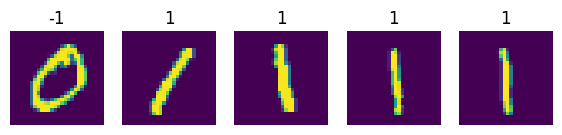

In [4]:
# Посмотрим на первые 5 примеров

n = 5

fig, axs = plt.subplots(1, n, figsize=(7, 3))

for ax, image, label in zip(axs, X_bin[:n], y_bin[:n]):

  # Переводим картинку из вектора длины 784 в матрицу 28 x 28
  image_reshaped = image.reshape(28, 28)

  ax.imshow(image_reshaped)
  ax.set_title(label)
  ax.axis("off")

### Шаг 1. Тренировка незащищенной модели [2 балла]


Начнем с того, что натренируем стандартную модель логистической регрессии и оценим ее устойчивость к атакам. Из курса ML вспомним, что логистическая регрессия это линейная модель:

$$h_\theta(x) = w^T x + b$$

с функцией ошибки

\begin{equation}
\ell(h_\theta(x), y) = \log(1+\exp(-y\cdot h_\theta(x))) \equiv L(y \cdot h_\theta(x))
\end{equation}

Здесь для сокращения записи мы ввели функцию $L(x) = \log(1+\exp(-x))$.


**Что нужно сделать:**

1. Разбить данные на train и test

2. Нормализовать датасет ($X$) так, чтобы значения каждого пикселя были в диапазоне [0, 1]

3. Натренировать модель логистической регрессии на train set

4. Оценить точность (accuracy) логистической регрессии на test set

Для решения этой части задания можно использовать встроенные методы `sklearn`



In [5]:
# Для решения могут пригодиться следующие методы

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score

# Your code here

RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(X_bin, y_bin, test_size=0.2, random_state=RANDOM_STATE)

scaler = MinMaxScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print(f'Logistic regression accuracy is {accuracy_score(y_test, y_pred):.5f}')


Logistic regression accuracy is 0.99966


### Шаг 2. Атака незащищенной модели [3 балла]

Будем считать, что мы можем атаковать модель, изменив значение каждого пикселя в изображении не более чем на 0.2 (атака производится после нормализации):

$$x' = x + \delta, \quad ||\delta||_{\infty} \le 0.2 = ɛ.$$

Как мы доказали на лекции, в случае логистической регрессии мы можем найти точное выражение для оптимальной атаки:
\begin{equation}
\delta^\star = - y \cdot \epsilon \cdot \mathrm{sign}(w),
\end{equation}
где $w$ это вектор весов модели, который мы получили на Шаге 1.

Давайте проведем атаку на модель и посмотрим как сильно упадет её точность.

**Что нужно сделать**

1. Вычислить значения оптимальной атаки $\delta^\star$ для каждого класса (-1 и 1)

2. Применить атаку к каждому изображению в test set

3. Оценить точность (accuracy) логистической регрессии на атакованном test set

Обратите внимание, что атака изображения может вывести значения пикселей из диапазона $[0, 1]$. Для простоты в этом задании можно не делать повторной нормализации.

Для решения этой части задания можно использовать встроенные методы `sklearn`

In [6]:
# TODO: Вычислите значения оптимальной атаки на картинки каждого класса и
# изобразите их

# Вектор весов модели можно получить следующим образом:
weight = lr.coef_

# Your code here
eps = 0.2

delta_neg = eps * np.sign(weight)
X_test_attacked = X_test.copy()
X_test_attacked[(y_test == -1)] = X_test[(y_test == -1)] + delta_neg
X_test_attacked[(y_test == 1)]  = X_test[(y_test == 1)] - delta_neg

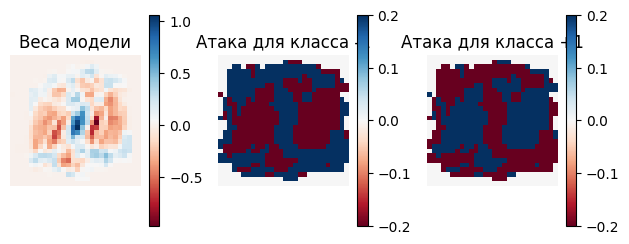

In [7]:
plt.subplot(2, 3, 4)
plt.imshow(weight.reshape(28, 28), cmap='RdBu')
plt.title('Веса модели')
plt.axis('off')
plt.colorbar()

plt.subplot(2, 3, 5)
plt.imshow(delta_neg.reshape(28, 28), cmap='RdBu', vmin=-eps, vmax=eps)
plt.title('Атака для класса -1')
plt.axis('off')
plt.colorbar()

plt.subplot(2, 3, 6)
plt.imshow(-delta_neg.reshape(28, 28), cmap='RdBu', vmin=-eps, vmax=eps)
plt.title('Атака для класса +1')
plt.axis('off')
plt.colorbar()

plt.tight_layout()
plt.show()

In [8]:
# TODO: Примените атаку к изображениям в test set и посчитайте точность модели

# Your code here
y_pred_attacked = lr.predict(X_test_attacked)

print(f'Logistic regression accuracy under attack is {accuracy_score(y_test, y_pred_attacked):.5f}')

Logistic regression accuracy under attack is 0.08424


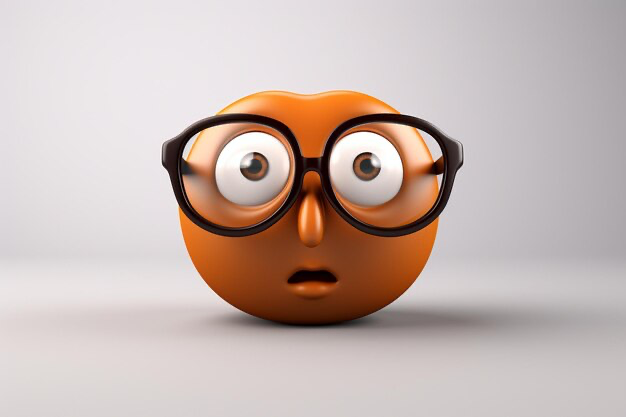

### Шаг 3. Тренировка Robust Classifier [5 баллов]

Чтобы натренировать модель, устойчивую к атакам, нужно изменить процесс тренировки. Во время тренировки нам нужно минимизировать не стандартную функцию ошибки логистической регрессии, а модифицированную:

\begin{equation}
\DeclareMathOperator*{\minimize}{minimize}
\minimize_{w,b} \frac{1}{D}\sum_{(x,y) \in D} L \left(y \cdot (w^Tx + b) - \epsilon \|w\|_1 \right ).
\end{equation}

Натренируйте модель Robust Logistic Regression на train set и оцените ее устойчивость к атакам.

**Что нужно сделать:**

1. Реализуйте свой ML-метод: класс **RobustLogisticRegression**, который наследует от sklearn класса [BaseEstimator](https://scikit-learn.org/stable/modules/generated/sklearn.base.BaseEstimator.html). Новый класс должен содержать методы `fit` и `predict`, а внутри метода `fit` должна проходить процедура градиентного спуска с новой функцией ошибки. Шаблон класса дан ниже.

2. Натренируйте Robust Logistic Regression и оцените ее точность на чистом test set

3. Вычислите атаку $\delta^\star = - y \cdot \epsilon \cdot \mathrm{sign}(w)$ на модель и проатакуйте test set. Для атаки используйте веса робастной модели

4. Оцените точность модели на атакованном test set

Для решения этой части задания **нельзя** использовать встроенные методы `sklearn`, только шаблон ниже и методы `numpy`

In [9]:
from sklearn.base import BaseEstimator

# TODO: Write RobustLogisticRegression class

class RobustLogisticRegression(BaseEstimator):

    def __init__(self, epsilon=0.2, learning_rate=0.1, n_iter=2000, random_state=42):
        # инициализируем модель
        self.epsilon = epsilon
        self.learning_rate = learning_rate
        self.n_iter = n_iter
        self.random_state = random_state
        self.w = None
        self.b = 0.0

    def fit(self, X, y):
        """Метод для тренировки модели по тренировочным данным X и y"""
        n_samples, n_features = X.shape

        rng = np.random.default_rng(self.random_state)
        self.w = rng.normal(loc=0.0, scale=0.01, size=n_features)
        self.b = 0.0

        for _ in range(self.n_iter):
            l1_norm = np.sum(np.abs(self.w))
            margins = y * (X @ self.w + self.b) - self.epsilon * l1_norm

            sigm = 1.0 / (1.0 + np.exp(margins))
            dloss_dm = -sigm

            sign_w = np.sign(self.w)
            dm_dw = y[:, None] * X - self.epsilon * sign_w[None, :]
            dm_db = y

            grad_w = np.mean(dloss_dm[:, None] * dm_dw, axis=0)
            grad_b = np.mean(dloss_dm * dm_db)

            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

        return self

    def predict(self, X):
        """Метод для предсказания классов для данных X"""
        scores = X @ self.w + self.b
        return np.where(scores >= 0, 1, -1)


In [ ]:
robust_lr = RobustLogisticRegression(epsilon=0.2, learning_rate=0.1, n_iter=2000, random_state=42)
robust_lr.fit(X_train, y_train)

y_pred_robust = robust_lr.predict(X_test)
print(f'Robust logistic regression accuracy on clean test set is: {accuracy_score(y_test, y_pred_robust):.5f}')

eps = robust_lr.epsilon
delta_neg_robust = eps * np.sign(robust_lr.w)

X_test_attacked_robust = X_test.copy()
X_test_attacked_robust[(y_test == -1)] = X_test[(y_test == -1)] + delta_neg_robust
X_test_attacked_robust[(y_test == 1)] = X_test[(y_test == 1)] - delta_neg_robust

y_pred_robust_attacked = robust_lr.predict(X_test_attacked_robust)
print(f'Robust logistic regression accuracy under attack is: {accuracy_score(y_test, y_pred_robust_attacked):.5f}')


Robust logistic regression accuracy on clean test set: 0.99696
Robust logistic regression accuracy under attack: 0.96922
